1 setup

In [1]:
!pip install -q segmentation-models-pytorch albumentations

import os, time, random, numpy as np, torch, torch.nn as nn
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from PIL import Image
import segmentation_models_pytorch as smp
from google.colab import drive

drive.mount("/content/drive")
if not os.path.exists("/content/patches"):
    !tar -xf /content/drive/MyDrive/lulc/patches.tar -C /content

CLASSES = ["urban_land", "agriculture_land", "rangeland",
           "forest_land", "water", "barren_land", "unknown"]
root = "/content/patches"
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
NUM_CLASSES, IGNORE = 6, 255
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

class PatchDS(Dataset):
    def __init__(self, split, train=False, limit=None):
        self.split = split
        self.files = sorted(os.listdir(f"{root}/{split}/img"))
        if limit:
            random.Random(0).shuffle(self.files)
            self.files = self.files[:limit]
        aug = [A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5), A.RandomRotate90(p=0.5),
               A.RandomBrightnessContrast(0.2, 0.2, p=0.5)] if train else []
        self.tf = A.Compose(aug + [A.Normalize(MEAN, STD), ToTensorV2()])
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        f = self.files[i]
        img = np.array(Image.open(f"{root}/{self.split}/img/{f}").convert("RGB"))
        m = np.array(Image.open(f"{root}/{self.split}/mask/{f.replace('.jpg', '.png')}"))
        m[m == 6] = IGNORE
        out = self.tf(image=img, mask=m)
        return out["image"], out["mask"].long()

model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=NUM_CLASSES).to(device)
ce = nn.CrossEntropyLoss(ignore_index=IGNORE)
dice = smp.losses.DiceLoss("multiclass", ignore_index=IGNORE)
def loss_fn(logits, y):
    return ce(logits, y) + dice(logits, y)

def confusion(pred, y, n=NUM_CLASSES):
    k = y != IGNORE
    return torch.bincount(y[k] * n + pred[k], minlength=n * n).reshape(n, n)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with autocast("cuda"):
            out = model(x)
        total += loss_fn(out.float(), y).item() * x.size(0)
        n += x.size(0)
        cm += confusion(out.argmax(1), y)
    cm = cm.float()
    iou = cm.diag() / (cm.sum(0) + cm.sum(1) - cm.diag()).clamp(min=1)
    return total / n, iou.cpu().numpy()

def run(epochs, train_limit=None, val_limit=None, lr=1e-4, bs=8,
        ckpt="/content/drive/MyDrive/lulc/best.pt"):
    tr = DataLoader(PatchDS("train", train=True, limit=train_limit), batch_size=bs,
                    shuffle=True, num_workers=2, pin_memory=True, drop_last=True)
    va = DataLoader(PatchDS("val", limit=val_limit), batch_size=bs,
                    num_workers=2, pin_memory=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    scaler = GradScaler("cuda")
    best = 0.0
    for ep in range(1, epochs + 1):
        model.train()
        t0, run_loss, steps = time.time(), 0.0, 0
        for x, y in tr:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast("cuda"):
                out = model(x)
            loss = loss_fn(out.float(), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            run_loss += loss.item(); steps += 1
        val_loss, iou = evaluate(model, va)
        miou = float(iou.mean())
        sched.step(miou)
        print(f"epoch {ep}/{epochs} | train loss {run_loss/steps:.3f} | val loss {val_loss:.3f} "
              f"| val mIoU {miou:.3f} | {time.time()-t0:.0f}s")
        print("   IoU:", {c: round(float(v), 3) for c, v in zip(CLASSES[:6], iou)})
        if miou > best:
            best = miou
            os.makedirs(os.path.dirname(ckpt), exist_ok=True)
            torch.save(model.state_dict(), ckpt)
            print("   saved best checkpoint")
    return best

# load the trained weights (epoch 6 checkpoint, val mIoU 0.710)
ckpt_path = "/content/drive/MyDrive/lulc/best.pt"
if os.path.exists(ckpt_path):
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    print("loaded best.pt")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda
loaded best.pt


Dataset and tile prediction

In [2]:
import json, matplotlib.pyplot as plt, matplotlib.patches as mpatches
import torch.nn.functional as F

# dataset location (Colab's Kaggle mount, with a download fallback)
path = "/kaggle/input/deepglobe-land-cover-classification-dataset"
if not os.path.exists(path):
    import kagglehub
    path = kagglehub.dataset_download("balraj98/deepglobe-land-cover-classification-dataset")
print("dataset:", path)

splits = json.load(open("/content/drive/MyDrive/lulc/splits.json"))

PALETTE = np.array([
    [0, 255, 255],    # urban
    [255, 255, 0],    # agriculture
    [255, 0, 255],    # rangeland
    [0, 255, 0],      # forest
    [0, 0, 255],      # water
    [255, 255, 255],  # barren
], dtype=np.uint8)

mean_t = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(STD, device=device).view(1, 3, 1, 1)

@torch.no_grad()
def predict_tile(img, win=512, stride=256, bs=4):
    """img: HxWx3 uint8 array. Returns HxW class-id array."""
    model.eval()
    H, W, _ = img.shape
    ys = list(range(0, H - win + 1, stride))
    xs = list(range(0, W - win + 1, stride))
    if ys[-1] != H - win: ys.append(H - win)
    if xs[-1] != W - win: xs.append(W - win)

    probs = torch.zeros(NUM_CLASSES, H, W, device=device)
    counts = torch.zeros(1, H, W, device=device)
    coords = [(y, x) for y in ys for x in xs]

    for i in range(0, len(coords), bs):
        batch = coords[i:i + bs]
        tiles = np.stack([img[y:y + win, x:x + win] for y, x in batch])
        t = torch.from_numpy(tiles).to(device).permute(0, 3, 1, 2).float() / 255.0
        t = (t - mean_t) / std_t
        with autocast("cuda"):
            p = F.softmax(model(t).float(), dim=1)
        for k, (y, x) in enumerate(batch):
            probs[:, y:y + win, x:x + win] += p[k]
            counts[:, y:y + win, x:x + win] += 1

    return (probs / counts).argmax(0).cpu().numpy().astype(np.uint8)

legend = [mpatches.Patch(fc=PALETTE[i] / 255.0, ec="black", label=CLASSES[i].replace("_", " "))
          for i in range(6)]

def rgb_to_ids(rgb):
    ids = np.full(rgb.shape[:2], 255, dtype=np.uint8)
    for i, c in enumerate(PALETTE):
        ids[(rgb == c).all(-1)] = i
    return ids

Using Colab cache for faster access to the 'deepglobe-land-cover-classification-dataset' dataset.
dataset: /kaggle/input/deepglobe-land-cover-classification-dataset


evaluation (confusion matrix)

Pixel accuracy: 0.870
Test mIoU:      0.706   mean F1: 0.815

class                 IoU     F1   prec recall
urban_land          0.773  0.872  0.879  0.866
agriculture_land    0.866  0.928  0.924  0.932
rangeland           0.380  0.551  0.553  0.548
forest_land         0.781  0.877  0.887  0.867
water               0.825  0.904  0.909  0.899
barren_land         0.610  0.758  0.750  0.766


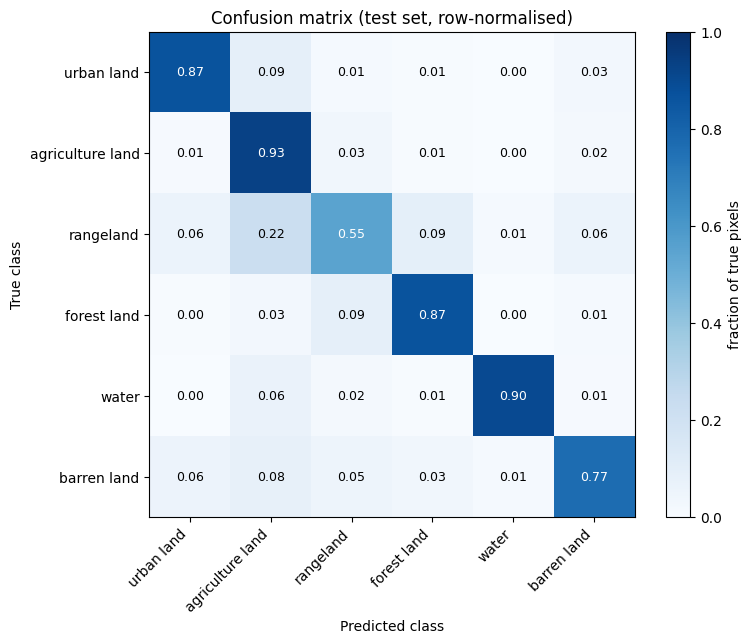

In [3]:
import matplotlib.pyplot as plt

model.eval()
test_dl = DataLoader(PatchDS("test"), batch_size=8, num_workers=2, pin_memory=True)

cm = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=device)
with torch.no_grad():
    for x, y in test_dl:
        x, y = x.to(device), y.to(device)
        with autocast("cuda"):
            out = model(x)
        cm += confusion(out.argmax(1), y)
cm = cm.float().cpu().numpy()

tp = np.diag(cm)
iou = tp / (cm.sum(0) + cm.sum(1) - tp)
prec = tp / cm.sum(0)
rec = tp / cm.sum(1)
f1 = 2 * prec * rec / (prec + rec)

print(f"Pixel accuracy: {tp.sum() / cm.sum():.3f}")
print(f"Test mIoU:      {iou.mean():.3f}   mean F1: {f1.mean():.3f}\n")
print(f"{'class':18s} {'IoU':>6s} {'F1':>6s} {'prec':>6s} {'recall':>6s}")
for i, c in enumerate(CLASSES[:6]):
    print(f"{c:18s} {iou[i]:6.3f} {f1[i]:6.3f} {prec[i]:6.3f} {rec[i]:6.3f}")

names = [c.replace("_", " ") for c in CLASSES[:6]]
norm = cm / cm.sum(1, keepdims=True)   # each row = true class, sums to 1

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(6)); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(names)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("Confusion matrix (test set, row-normalised)")
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center",
                color="white" if norm[i, j] > 0.5 else "black", fontsize=9)
plt.colorbar(im, label="fraction of true pixels")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/lulc/confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
. Example predictions (code cell)

The figure cell that makes 8 tile figures with the legend.

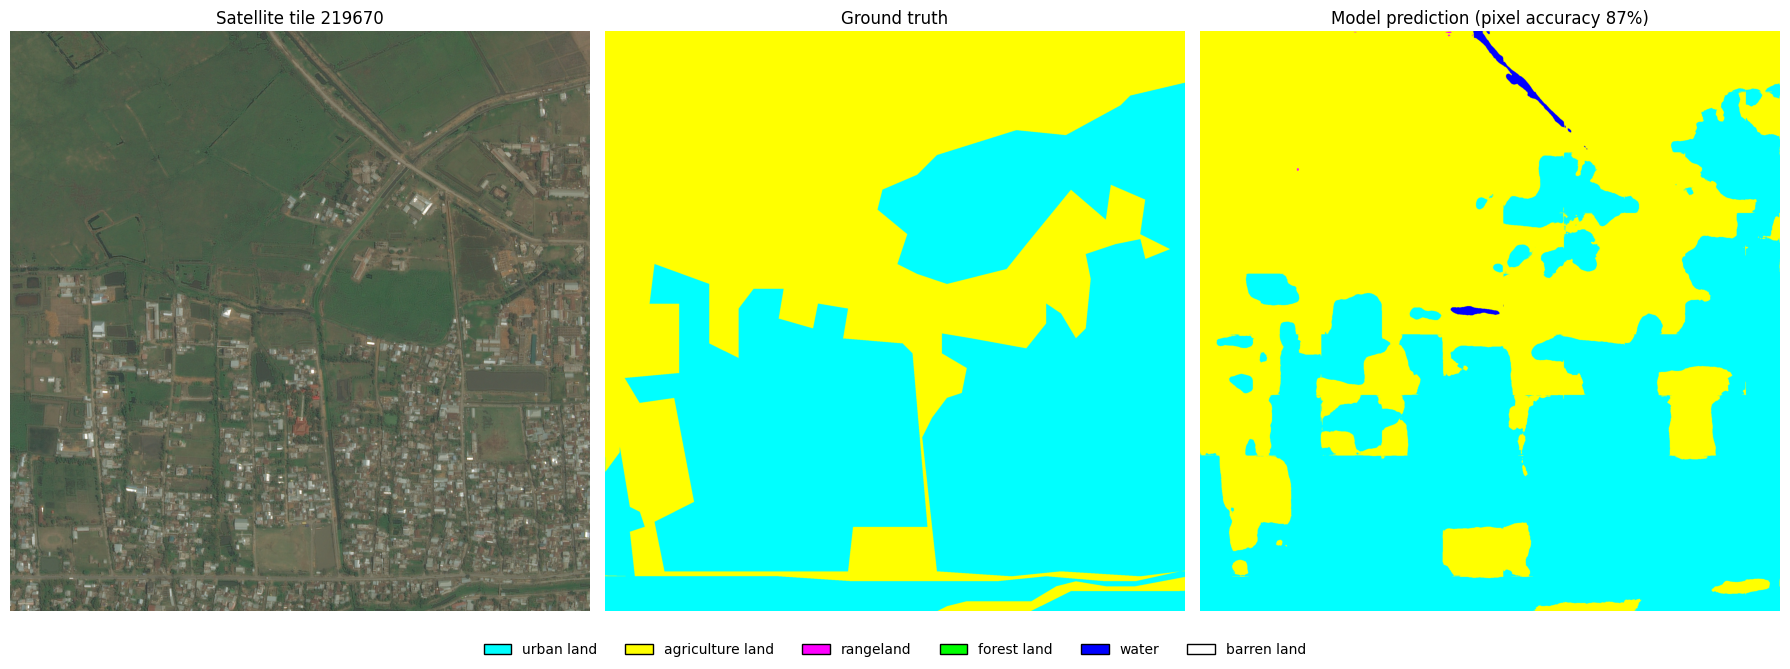

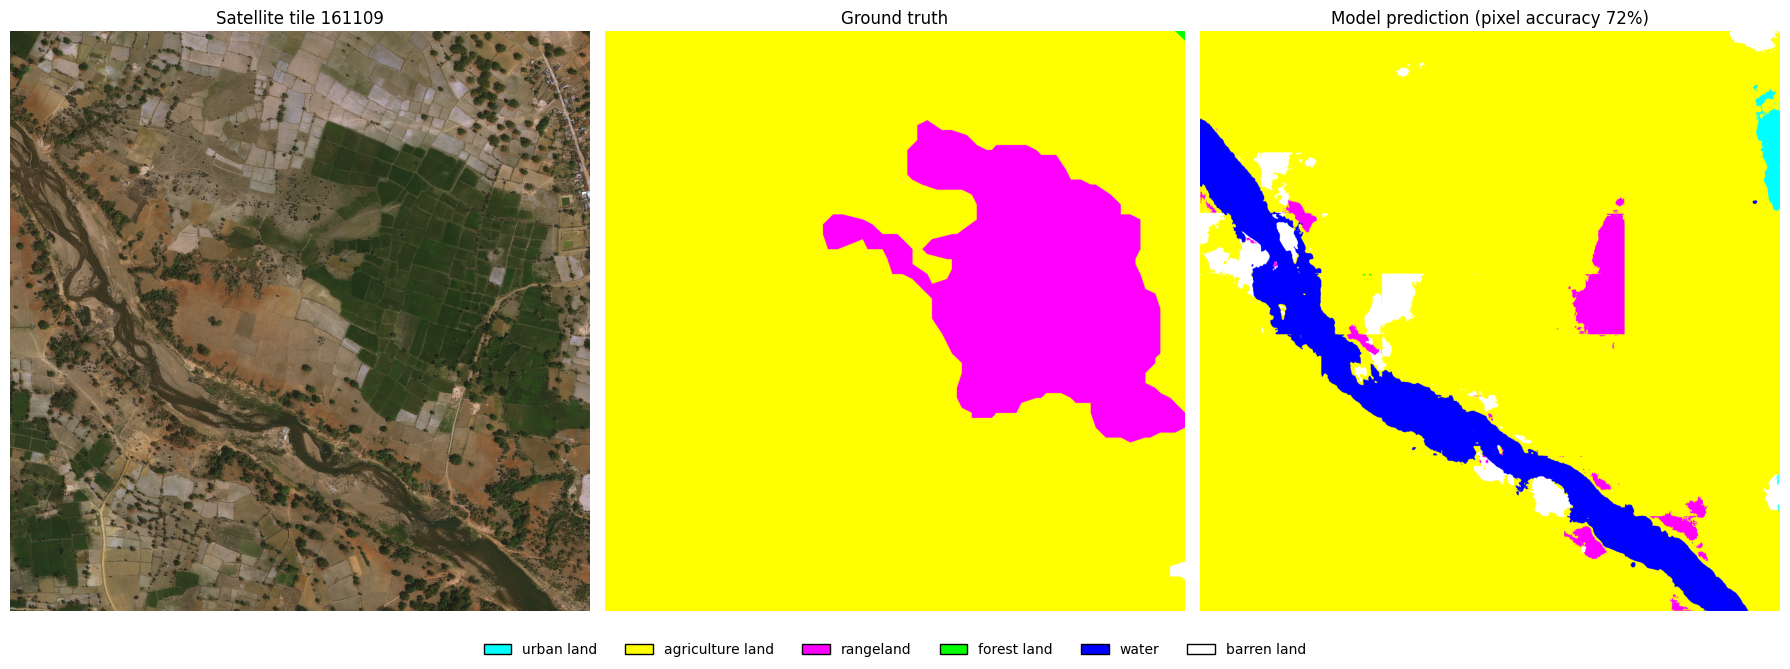

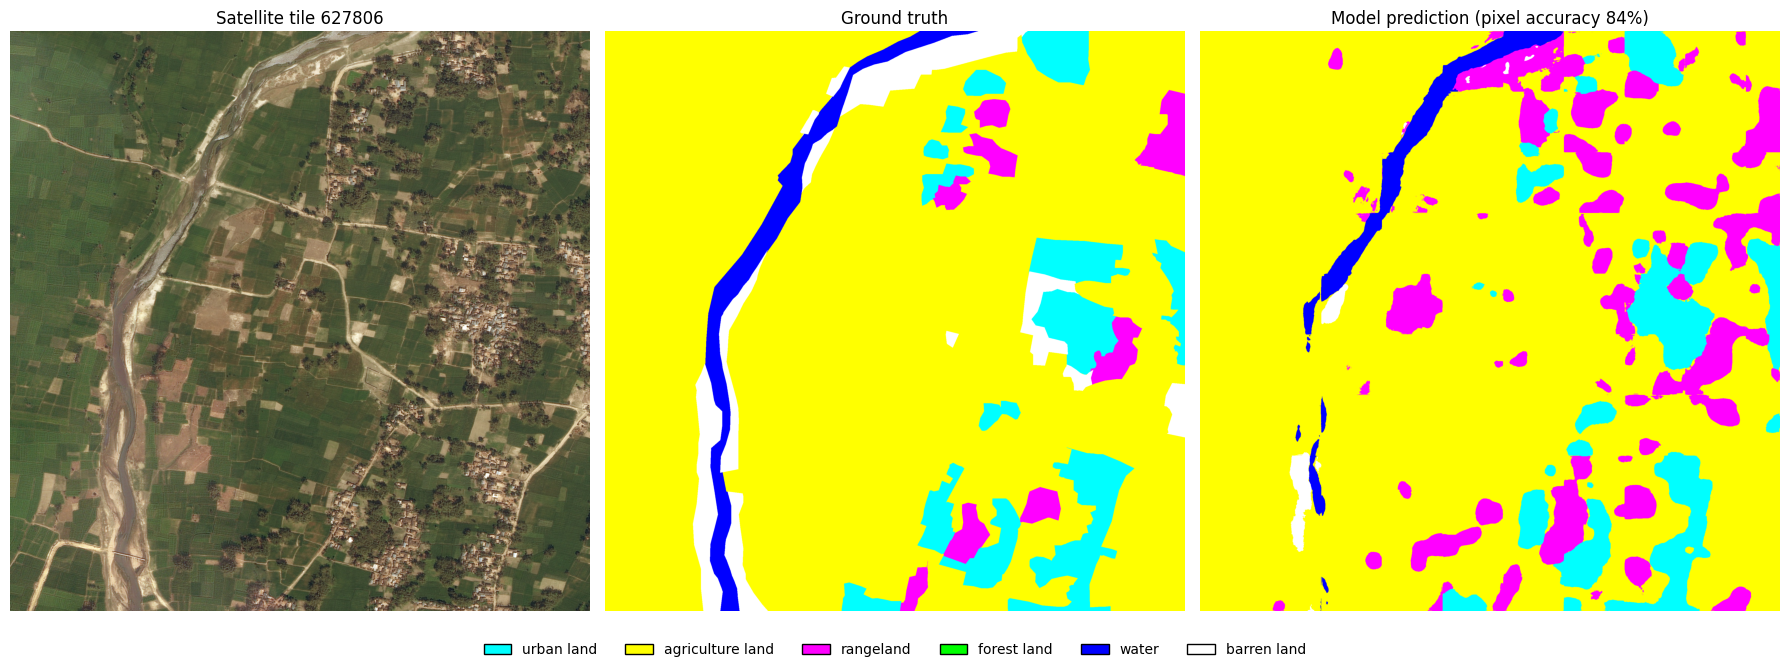

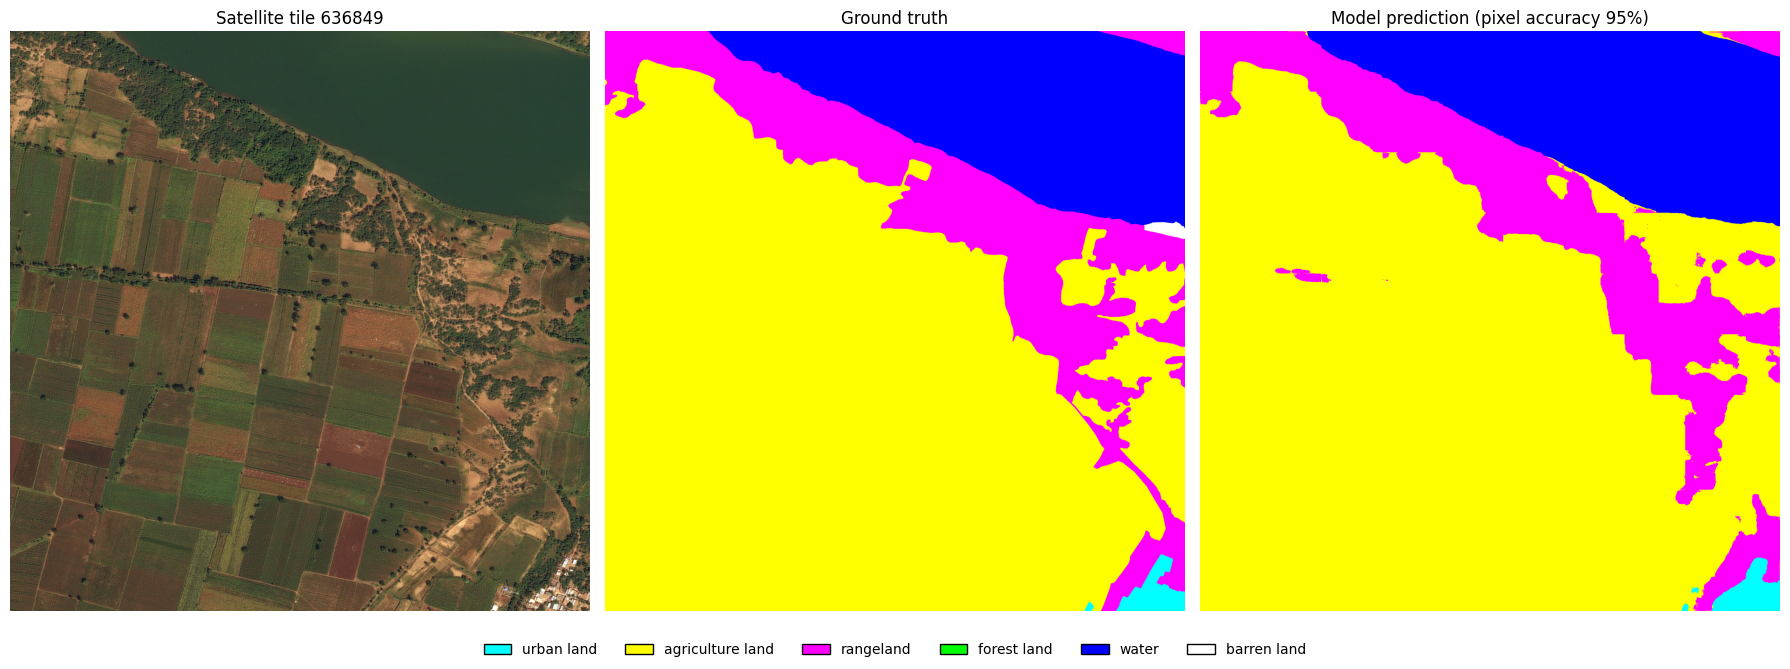

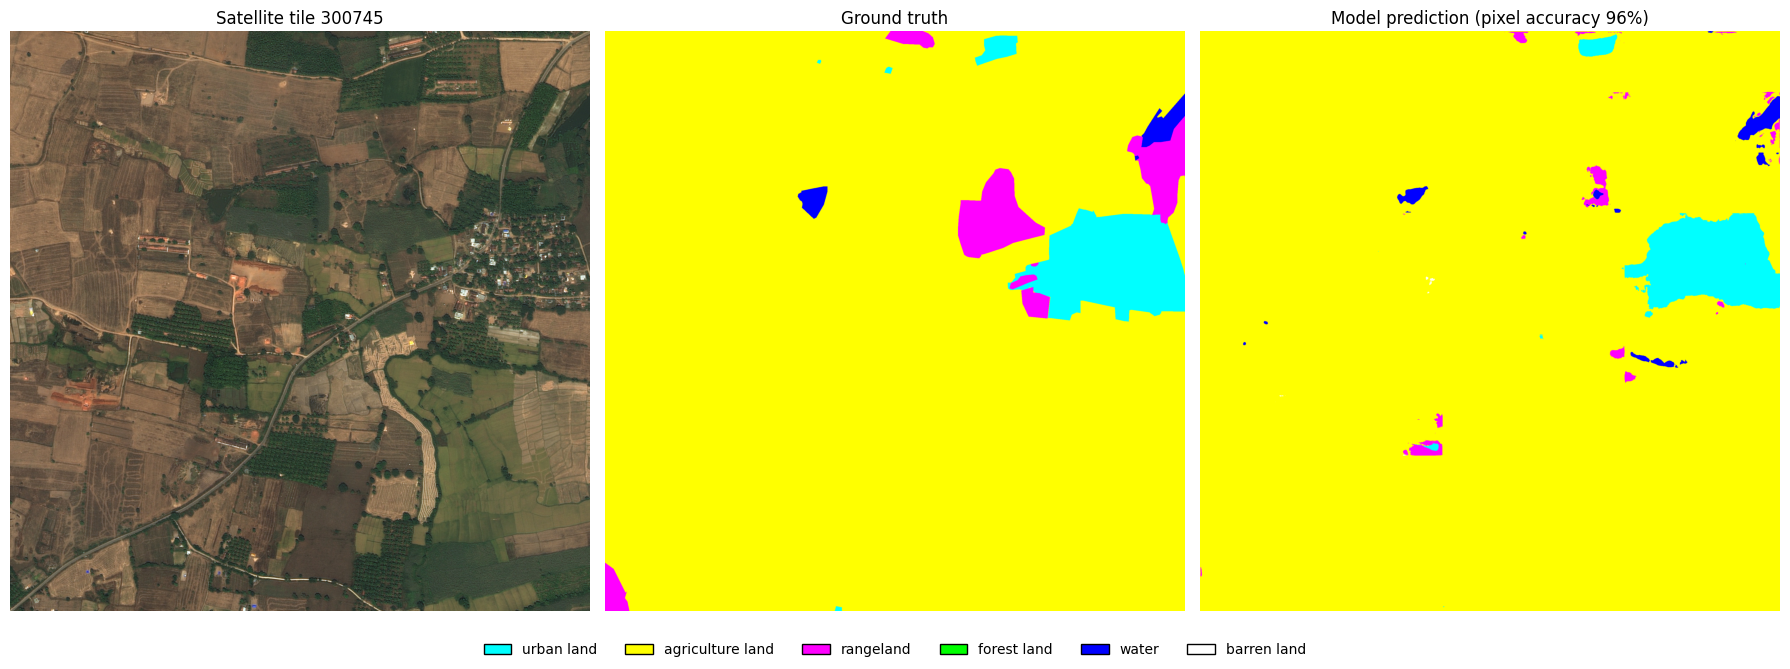

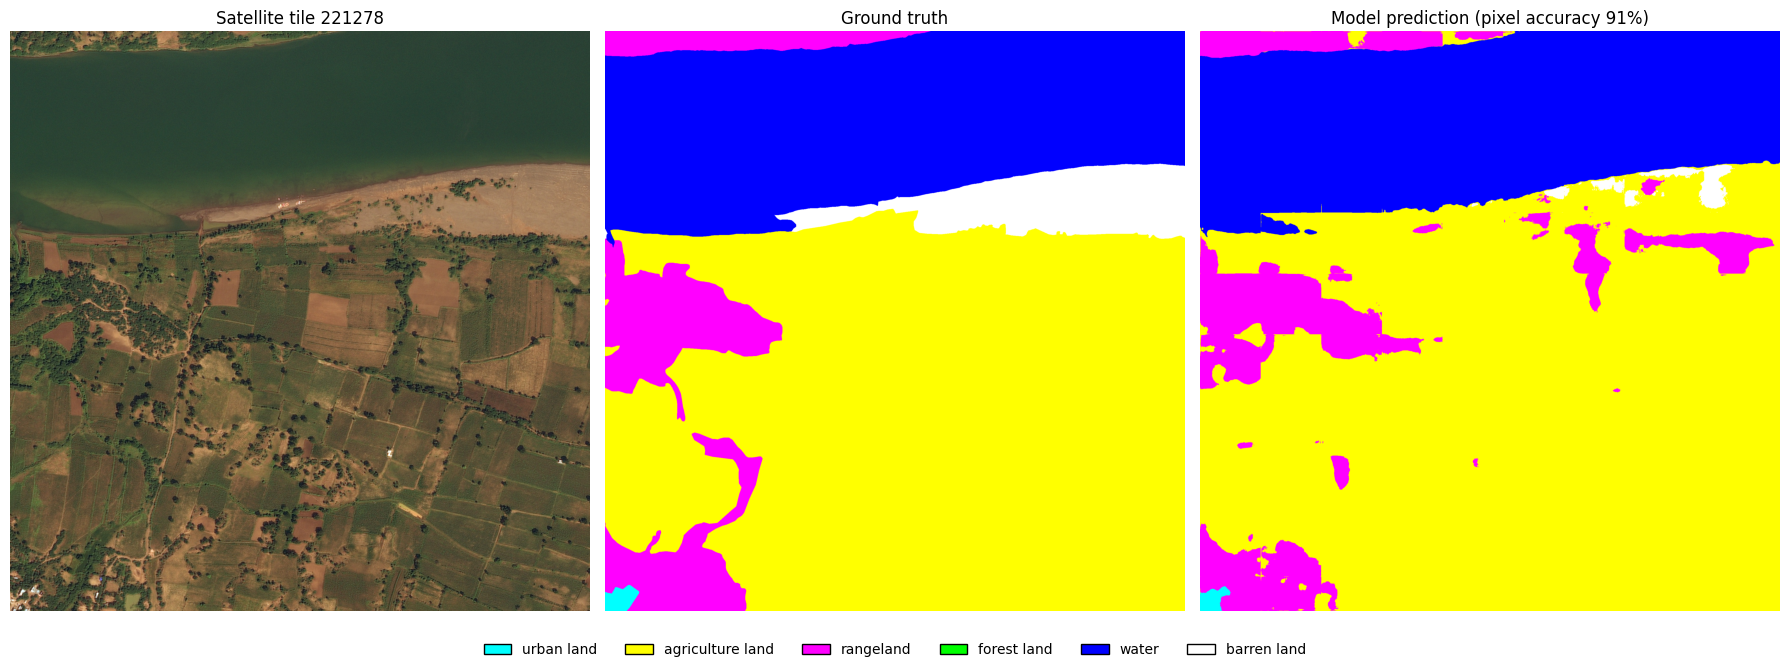

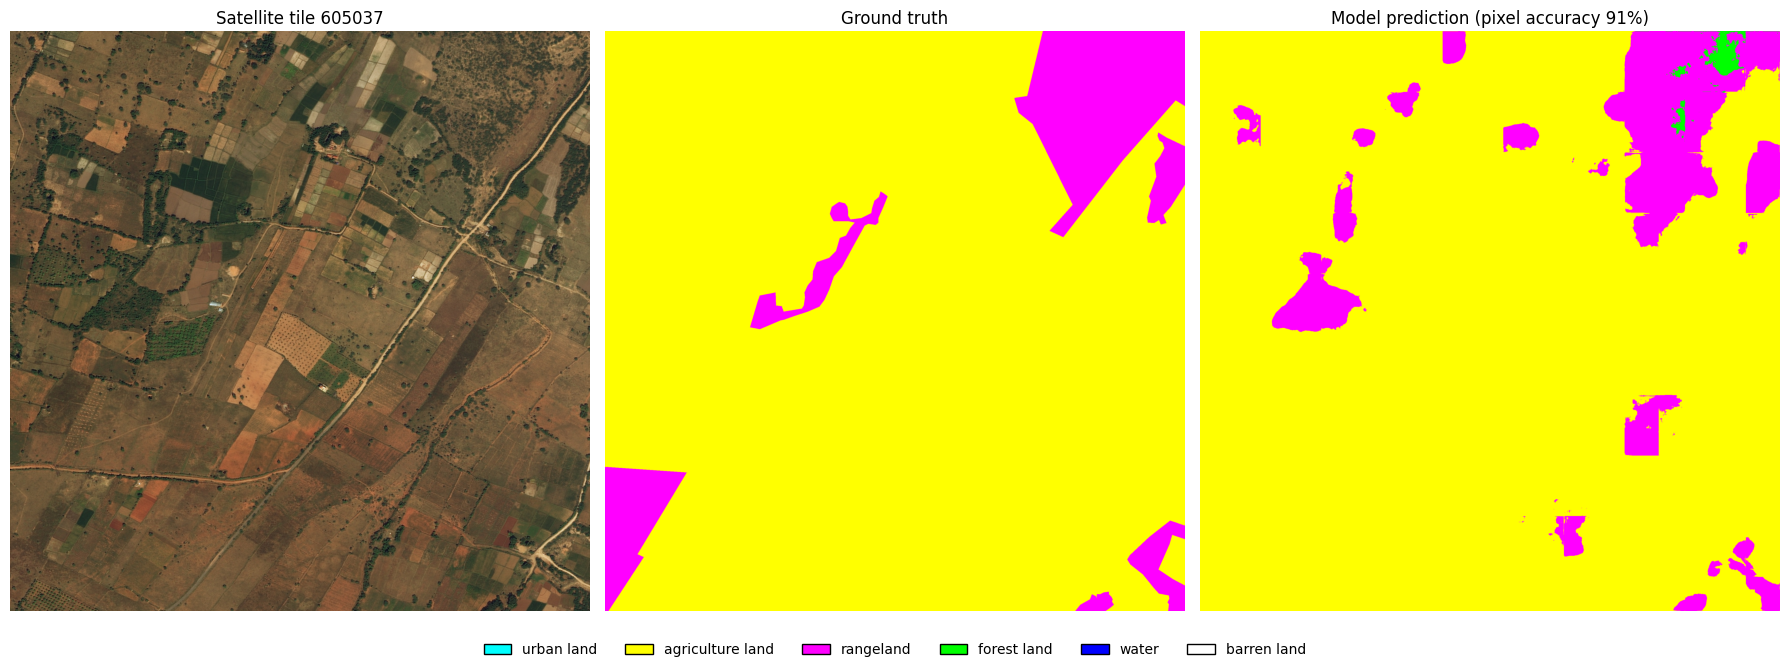

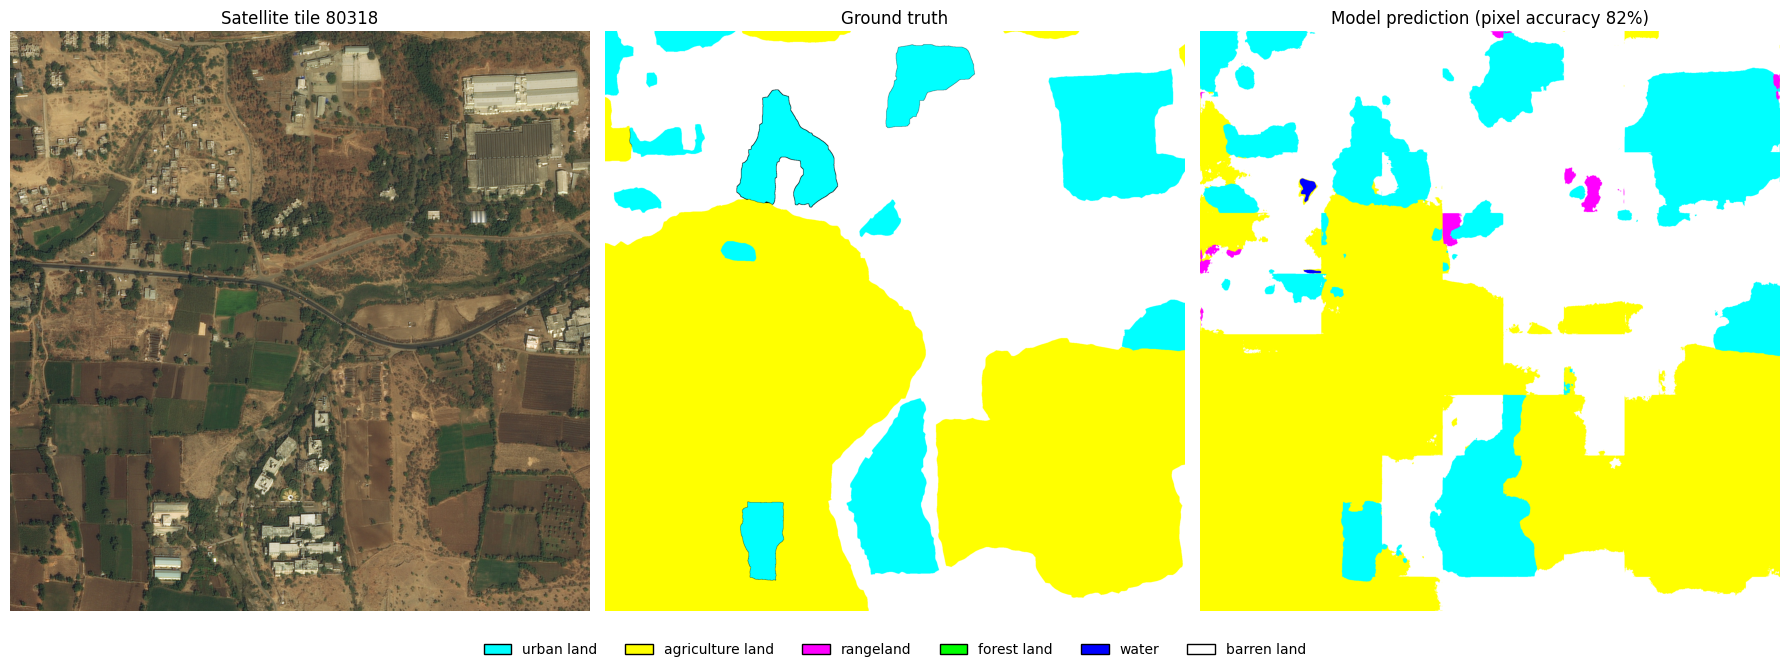

In [4]:
os.makedirs("/content/drive/MyDrive/lulc/figures", exist_ok=True)

N = 8
rng = np.random.default_rng(1)
chosen = rng.choice(splits["test"], size=N, replace=False)

for img_id in chosen:
    img = np.array(Image.open(f"{path}/train/{img_id}_sat.jpg").convert("RGB"))
    true_rgb = np.array(Image.open(f"{path}/train/{img_id}_mask.png").convert("RGB"))
    pred = predict_tile(img)

    gt = rgb_to_ids(true_rgb)
    valid = gt != 255
    acc = (pred[valid] == gt[valid]).mean()

    fig, ax = plt.subplots(1, 3, figsize=(18, 6.5))
    ax[0].imshow(img);              ax[0].set_title(f"Satellite tile {img_id}")
    ax[1].imshow(true_rgb);         ax[1].set_title("Ground truth")
    ax[2].imshow(PALETTE[pred]);    ax[2].set_title(f"Model prediction (pixel accuracy {acc:.0%})")
    for a in ax: a.axis("off")
    fig.legend(handles=legend, loc="lower center", ncol=6, frameon=False)
    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.savefig(f"/content/drive/MyDrive/lulc/figures/{img_id}.png", dpi=150)
    plt.show()

Section 5: Appendix, how the model was made

In [7]:
import pandas as pd
from tqdm.auto import tqdm

PATCH = 512
starts = np.linspace(0, 2448 - PATCH, 5).astype(int)   # 5x5 grid with overlap = 25 patches per image
out_root = "/content/patches"

COLORS = np.array([[0,255,255],[255,255,0],[255,0,255],[0,255,0],[0,0,255],[255,255,255],[0,0,0]], dtype=np.uint8)
code_to_id = {int(r)*65536 + int(g)*256 + int(b): i for i, (r, g, b) in enumerate(COLORS)}

def mask_to_ids_fast(mask_path):
    m = np.array(Image.open(mask_path).convert("RGB")).astype(np.int64)
    code = m[..., 0]*65536 + m[..., 1]*256 + m[..., 2]
    out = np.full(code.shape, 255, dtype=np.uint8)
    for c, i in code_to_id.items():
        out[code == c] = i
    return out

def make_patches(split, img_id):
    sat = Image.open(f"{path}/train/{img_id}_sat.jpg").convert("RGB")
    ids_ = mask_to_ids_fast(f"{path}/train/{img_id}_mask.png")
    for r in starts:
        for c in starts:
            sat.crop((c, r, c + PATCH, r + PATCH)).save(
                f"{out_root}/{split}/img/{img_id}_{r}_{c}.jpg", quality=95)
            Image.fromarray(ids_[r:r + PATCH, c:c + PATCH]).save(
                f"{out_root}/{split}/mask/{img_id}_{r}_{c}.png")

if os.path.exists(f"{out_root}/train/img"):
    print("patches already exist, skipping")
else:
    for s in splits:
        os.makedirs(f"{out_root}/{s}/img", exist_ok=True)
        os.makedirs(f"{out_root}/{s}/mask", exist_ok=True)
    for split, id_list in splits.items():
        for img_id in tqdm(id_list, desc=split):
            make_patches(split, img_id)
    !cd /content && tar -cf /content/drive/MyDrive/lulc/patches.tar patches
    print("patches built and backed up to Drive")

patches already exist, skipping


In [ ]:
# WARNING: this retrains the model. It saves to a NEW file so your good best.pt is not overwritten.
best = run(epochs=8, train_limit=None, val_limit=600,
           ckpt="/content/drive/MyDrive/lulc/best_retrain.pt")
print("best val mIoU:", best)